# R Basics for Genomics

Prepared By: Udayaraja GK

Supervised By: Haja N Kadarmideen

### Learning objectives

- R's basic **data types** and **data structures**;
- build and subset **vectors, factors, matrices, data frames, and lists**;
- use **operators**, write a small **function**, **read in and inspect** data, do light **data wrangling**, and **write results and plots to file**.

### Run this in Google Colab
1. Open in Colab → **Runtime → Change runtime type → `R` → Save** (needs the R kernel, not Python).
2. Run each cell with **Shift+Enter**, top to bottom.


## 1. R and RStudio

**R** is a free language for statistics and graphics — a top choice in genomics for modelling and figures. **RStudio** is the popular desktop app (editor + console + plots) for writing R. Here we use **Google Colab's R runtime** instead, so nothing needs installing; the R is identical.

You talk to R by **assigning** values to named objects with `<-` (think of a name as a labelled bucket).

In [ ]:
n_dogs <- 4      # store the value 4 in an object called n_dogs
n_dogs           # type an object's name to print it

[1] 4

## 2. Data types

Every value has a **type**. The four you meet constantly:

| Type | Example | Meaning |
|---|---|---|
| `numeric` | `30.5` | numbers (decimals) |
| `integer` | `2L` | whole numbers (the `L` makes it integer) |
| `character` | `"Labrador"` | text, in quotes |
| `logical` | `TRUE` / `FALSE` | yes/no values |

Check any value's type with `class()`.

In [ ]:
weight <- 30.5        # numeric
breed  <- "Labrador"  # character
typed  <- TRUE        # logical
class(weight); class(breed); class(typed)

[1] "numeric"

[1] "character"

[1] "logical"

## 3. Operators

**Operators** combine values: arithmetic (`+ - * / ^`), relational (`> >= == !=`, which return `TRUE`/`FALSE`), and logical (`&` and, `|` or, `!` not). These become your data filters later.

In [ ]:
weight > 25            # relational -> TRUE
weight * 2             # arithmetic
(weight > 25) & typed  # logical AND of two TRUE/FALSE values

[1] TRUE

[1] 61

[1] TRUE

## 4. Data structures — overview

A **data structure** holds many values together. The five you will use:

- **vector** — a 1-D sequence of one type (a column of values);
- **factor** — a vector for *categories* with fixed levels;
- **matrix** — a 2-D grid of one type (how genotypes are stored);
- **data frame** — a table whose columns can be different types (the phenotype table);
- **list** — a flexible container that can hold any of the above.

We meet each one now, building our dog dataset as we go.

## 5. Vectors

A **vector** is made with `c()` (combine). Here are two vectors describing four dogs — their weights and breeds. R applies operations to the *whole* vector at once (no loop needed).

In [ ]:
weights <- c(2.5, 30.5, 62.0, 11.0)                       # numeric vector: body weight (kg)
breeds  <- c("Chihuahua","Labrador","GreatDane","Beagle") # character vector: breed
length(weights)   # how many elements?
weights[2]        # the 2nd element (R counts from 1)
weights * 2       # operate on all elements at once

[1] 4

[1] 30.5

[1]   5  61 124  22

> **Exercise 1.** Make a numeric vector `heights` with four values (cm): 20, 57, 80, 38. Then print the height of the 3rd dog and the mean of all heights (`mean(heights)`).

## 6. Factors

A **factor** stores a *categorical* variable with a fixed set of **levels**. Set the level order yourself so R (and your plots and models) treat the categories sensibly. Behind the scenes a factor is stored as integer codes, one per level.

In [ ]:
size   <- c("small","large","large","medium")            # a category per dog
size_f <- factor(size, levels = c("small","medium","large"))  # fix the natural order
size_f
levels(size_f)        # the allowed categories, in order
as.numeric(size_f)    # the hidden integer codes: small=1, medium=2, large=3

[1] small  large  large  medium
Levels: small medium large

[1] "small"  "medium" "large"

[1] 1 3 3 2

> **Exercise 2.** Make a factor `sex_f` from `c("F","M","M","F")`. How many dogs are in each level? *(Hint: `table(sex_f)`.)*

## 7. Matrix

A **matrix** is a 2-D grid where every value is the same type — the natural way to store **genotypes**: rows = dogs, columns = SNPs, values = alt-allele dosage (0, 1, or 2). Index with `[row, column]`.

In [ ]:
geno <- matrix(c(0,1,2,
                 1,1,0), nrow = 2, byrow = TRUE,
               dimnames = list(c("dog1","dog2"), c("snp1","snp2","snp3")))
geno
dim(geno)               # rows, columns
geno["dog1", "snp3"]    # dog1's genotype at snp3

,snp1,snp2,snp3
dog1,0,1,2
dog2,1,1,0


[1] 2 3

[1] 2

## 8. Data frames

A **data frame** is a table whose columns may be *different* types — the standard **phenotype table**, one row per sample. Build one by combining the vectors we already made.

In [ ]:
dogs <- data.frame(breed     = breeds,
                   weight_kg = weights,
                   size      = size_f,
                   stringsAsFactors = FALSE)
dogs
str(dogs)   # 'structure': column names, types, and first values

breed,weight_kg,size
<chr>,<dbl>,<fct>
Chihuahua,2.5,small
Labrador,30.5,large
GreatDane,62.0,large
Beagle,11.0,medium


'data.frame':	4 obs. of  3 variables:
 $ breed    : chr  "Chihuahua" "Labrador" "GreatDane" "Beagle"
 $ weight_kg: num  2.5 30.5 62 11
 $ size     : Factor w/ 3 levels "small","medium",..: 1 3 3 2


> **Exercise 3.** Print just the `weight_kg` column two ways: `dogs$weight_kg` and `dogs[, "weight_kg"]`. Then print the whole first row with `dogs[1, ]`.

## 9. Lists

A **list** can hold different kinds of objects together — a data frame, a matrix, a single number — even nested. Most analysis results in R are lists. Access parts with `$name` or `[[ ]]`.

In [ ]:
results <- list(dogs = dogs, genotypes = geno, n = n_dogs)
results$n                       # the single number
results[["dogs"]]$weight_kg     # reach into the data frame inside the list

[1] 4

[1]  2.5 30.5 62.0 11.0

## 10. Functions

A **function** is reusable code: give it inputs (arguments), it returns a result. You already used built-ins (`mean()`, `length()`). Writing your own is simple — here, kilograms to pounds.

In [ ]:
kg_to_lb <- function(kg) {   # 'kg' is the input
  kg * 2.205                 # the last line is what the function returns
}
kg_to_lb(weights)            # runs on every element of the vector

[1]   5.5125  67.2525 136.7100  24.2550

## 11. Reading in and inspecting data

Real data comes from files. `read.csv()` reads a comma-separated file (here we pass text inline instead of a path). **Always inspect** before trusting it: `str()`, `head()`, `summary()`, `nrow()`.

In [ ]:
csv <- "breed,weight_kg
Chihuahua,2.5
Labrador,30.5
GreatDane,62
Beagle,11"
d <- read.csv(text = csv)     # in real use: read.csv("myfile.csv")
str(d)                        # types + preview
summary(d$weight_kg)          # min / median / mean / max

'data.frame':	4 obs. of  2 variables:
 $ breed    : chr  "Chihuahua" "Labrador" "GreatDane" "Beagle"
 $ weight_kg: num  2.5 30.5 62 11


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  2.500   8.875  20.750  26.500  38.375  62.000 

## 12. Data wrangling: data frames, matrices and lists

**Wrangling** = filtering and summarising. Rows are chosen with a `TRUE`/`FALSE` condition inside `[ ]`. The same ideas apply to matrices (by column) and lists (with `sapply`).

In [ ]:
# data frame: keep dogs over 20 kg
dogs[dogs$weight_kg > 20, ]

# matrix: alt-allele frequency per SNP = column mean / 2 (vectorised, no loop)
colMeans(geno) / 2

# list: apply a function to every element
sapply(list(a = c(0,1,2), b = c(2,2,1,0)), mean)

,breed,weight_kg,size
,<chr>,<dbl>,<fct>
2,Labrador,30.5,large
3,GreatDane,62.0,large


snp1 snp2 snp3 
0.25 0.50 0.50

a    b 
1.00 1.25

> **Optional — a friendlier syntax.** The **dplyr** package reads like English and is worth learning next: `library(dplyr); filter(dogs, weight_kg > 20)` does the same as the base-R filter above.

## 13. Writing to file and exporting plots

Save a table with `write.csv()`, and export a figure with `ggsave()` (from **ggplot2**, R's main plotting package: map columns to the plot with `aes()`, add a `geom_*` layer).

> **Colab note:** files save into the session's working folder — open the **Files** panel on the left, then right-click → *Download*. Colab storage is **temporary**, so download anything you want to keep.

[1] "dogs.csv" "dogs.png"

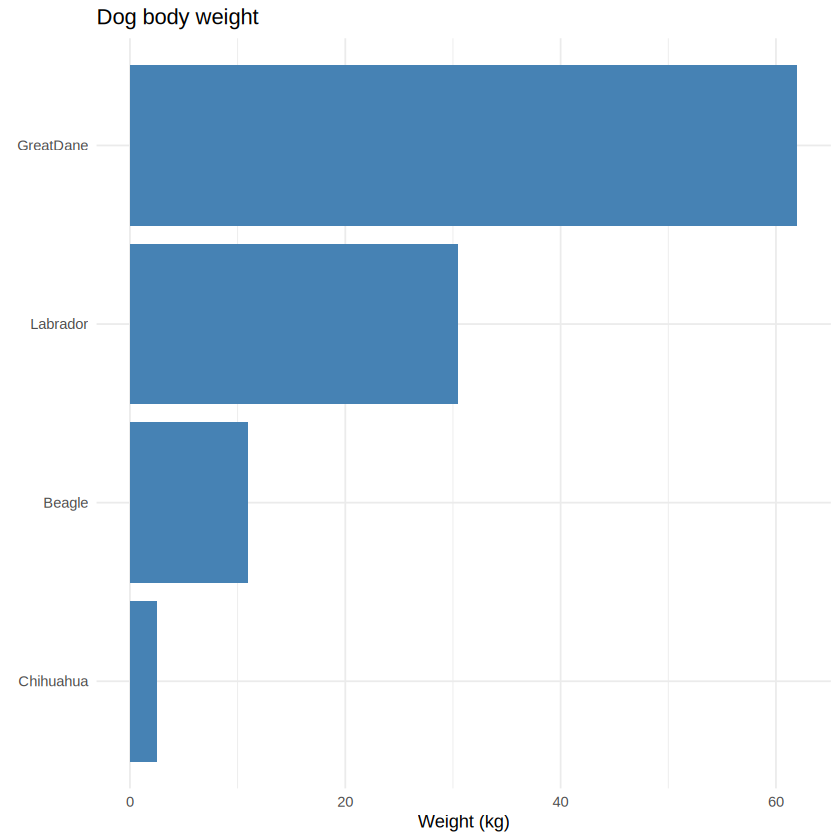

In [ ]:
write.csv(dogs, "dogs.csv", row.names = FALSE)   # save the table

library(ggplot2)
p <- ggplot(dogs, aes(x = reorder(breed, weight_kg), y = weight_kg)) +
  geom_col(fill = "steelblue") + coord_flip() +
  labs(x = NULL, y = "Weight (kg)", title = "Dog body weight") +
  theme_minimal()
p
ggsave("dogs.png", p, width = 4, height = 3, dpi = 120)   # export the plot
list.files(pattern = "dogs")                              # confirm both files exist

## Summary

Built one  dataset from the ground up and, along the way, covered every core R basic:
**R & RStudio** and assignment · **data types** · **operators** · **data structures** · **vectors** · **factors** · **matrices** (genotypes) · **data frames** (phenotypes) · **lists** · **functions** · **reading in & inspecting** data · **wrangling** across data frames/matrices/lists · **writing to file & exporting plots**.


### Further reading

- *R for Data Science* (Wickham, Çetinkaya-Rundel & Grolemund) — data frames, reading data, dplyr.
- The base R cheatsheet and the **dplyr** cheatsheet (search "posit cheatsheets").

---
*Next — **Module 2: Linux / command-line for bioinformatics** — the filesystem and `grep`/`sed`/`awk` on toy VCF/PLINK files, feeding the GWAS in Module 3.*